# 01 · Square → circle in 2D, via NiftyReg

The idea DRIFT is built on: register two images with a **stationary velocity field** (SVF) `v`, then treat
`exp(t·v)` as a trajectory. Any real `t` gives a smooth, invertible deformation, so `t ∈ [0, 1]`
interpolates between the shapes and `t < 0`, `t > 1` extrapolate.

Requires the `io` and `viz` extras and NiftyReg on `PATH` (or `NIFTYREG_BIN` set).

In [ ]:
import os
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt

from drift.filters import gaussian_smooth
from drift.flow import exp
from drift.grid import identity, warp
from drift.io import save_nifti
from drift.jacobian import det
from drift.registration.niftyreg import NiftyReg, NiftyRegParams
from drift.space import ImageSpace

# Use the project-local NiftyReg build if there is one.
local = Path("..") / "third_party" / "niftyreg" / "install" / "bin"
if "NIFTYREG_BIN" not in os.environ and local.is_dir():
    os.environ["NIFTYREG_BIN"] = str(local.resolve())

## Two shapes

A square (reference A) and a circle (floating B), lightly blurred so the similarity measure has gradients
to follow.

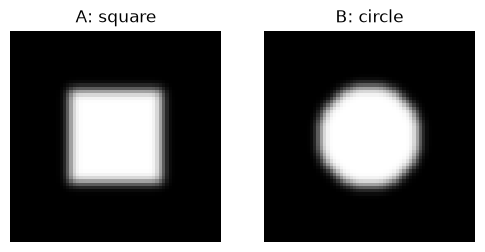

In [ ]:
n = 64
x = identity((n, n)) - (n - 1) / 2
square = gaussian_smooth((x.abs().amax(1, keepdim=True) <= 13.5).float(), 1.5)
circle = gaussian_smooth((x.norm(dim=1, keepdim=True) <= 15.5).float(), 1.5)
space = ImageSpace.from_spacing((n, n), spacing=1.5)

tmp = Path(tempfile.mkdtemp())
save_nifti(tmp / "square.nii.gz", square, space)
save_nifti(tmp / "circle.nii.gz", circle, space)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for a, img, title in zip(ax, (square, circle), ("A: square", "B: circle"), strict=True):
    a.imshow(img[0, 0], cmap="gray")
    a.set_title(title)
    a.axis("off")

## Register

`reg_aladin` (affine), then `reg_f3d -vel` on the affinely aligned circle. `exp(v)` pulls B back onto A's grid,
so `A ∘ exp(-t·v)` moves A towards B's shape. Both images share one contrast, so SSD is used here; NMI is
the default for MRI.

In [ ]:
params = NiftyRegParams(
    cp_spacing=-4.0, similarity="ssd", bending_energy=0.0005, linear_elasticity=0.0
)
result = NiftyReg(params).register(tmp / "square.nii.gz", tmp / "circle.nii.gz")
v = result.velocity
print(
    f"max |v| = {float(v.norm(dim=1).max()):.2f} voxels, det J range "
    f"[{float(result.jacobian.min):.2f}, {float(result.jacobian.max):.2f}], qc = {result.qc}"
)

max |v| = 3.27 voxels, det J range [0.72, 1.34], qc = {'nmi_affine': 1.21295, 'nmi': 1.36789}


## Sweep `t`

`t = 0` is the square and `t = 1` the circle. Going past 1 keeps pulling the corners in and pushing the edge
midpoints out, towards a diamond. `t = -1` goes the other way, past the square. The bottom row is `det J`,
which stays positive throughout.

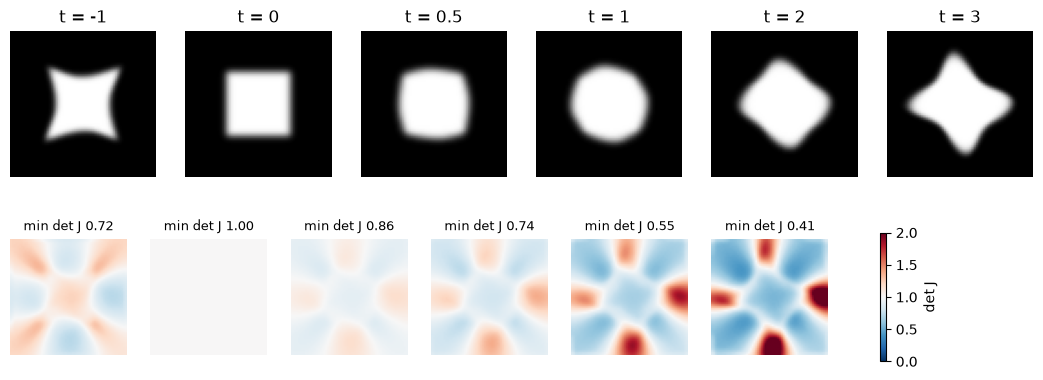

In [ ]:
ts = [-1.0, 0.0, 0.5, 1.0, 2.0, 3.0]
fig, ax = plt.subplots(2, len(ts), figsize=(2.2 * len(ts), 4.6))
for i, t in enumerate(ts):
    phi = exp(v, -t)
    ax[0, i].imshow(warp(square, phi)[0, 0], cmap="gray", vmin=0, vmax=1)
    ax[0, i].set_title(f"t = {t:g}")
    dj = det(phi)[0]
    im = ax[1, i].imshow(dj, cmap="RdBu_r", vmin=0, vmax=2)
    ax[1, i].set_title(f"min det J {float(dj.min()):.2f}", fontsize=9)
    for a in ax[:, i]:
        a.axis("off")
fig.colorbar(im, ax=ax[1], shrink=0.8, label="det J")

## Why not just scale the displacement?

The naive alternative takes the `t = 1` displacement `u` and uses `t·u`. Its paths are straight lines that can
cross, so it eventually folds (det J ≤ 0; here by `t = 6`), while `exp(t·v)` stays fold-free for every `t`.

In [ ]:
u = exp(v)
for t in (1.0, 2.0, 3.0, 4.0, 6.0):
    naive = float((det(t * u) <= 0).float().mean())
    svf = float((det(exp(v, t)) <= 0).float().mean())
    print(f"t = {t:g}: folded fraction, scaled displacement {naive:.4f} | exp(t·v) {svf:.4f}")

t = 1: folded fraction, scaled displacement 0.0000 | exp(t·v) 0.0000
t = 2: folded fraction, scaled displacement 0.0000 | exp(t·v) 0.0000
t = 3: folded fraction, scaled displacement 0.0000 | exp(t·v) 0.0000
t = 4: folded fraction, scaled displacement 0.0000 | exp(t·v) 0.0000
t = 6: folded fraction, scaled displacement 0.2461 | exp(t·v) 0.0000
